In [1]:
#importing librabries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#loading datasets
air = pd.read_csv(r"C:\Users\reddy\OneDrive\Desktop\ML\Dataset\air_quality_daily.csv")
cities = pd.read_csv(r"C:\Users\reddy\OneDrive\Desktop\ML\Dataset\cities.csv")
weather = pd.read_csv(r"C:\Users\reddy\OneDrive\Desktop\ML\Dataset\weather_daily.csv")

In [3]:
#convert dates
air["date"] = pd.to_datetime(air["date"])
weather["date"] = pd.to_datetime(weather["date"])

print("All datasets are loaded")
print(air.shape, cities.shape, weather.shape)

All datasets are loaded
(77400, 19) (50, 6) (124750, 14)


In [4]:
#merge air quality and weather
merged = pd.merge(
    air,
    weather,
    on = ["date", "city"],
    how = "left",
    validate = "one_to_one"
)

#Add geographical information
merged = pd.merge(
    merged,
    cities,
    on = "city",
    how = "left",
    validate = "many_to_one"
)

merged = merged.sort_values(
    ["city", "date"]
).reset_index(drop = True)

print("Integrated dataset:", merged.shape)
display(merged.head())

Integrated dataset: (77400, 36)


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,...,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code,state,region,latitude,longitude,elevation_m
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,...,10.5,150,21.19,4.63,63,Tripura,Northeast,23.8315,91.2868,12.0
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,...,8.8,125,17.90,3.89,63,Tripura,Northeast,23.8315,91.2868,12.0
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,...,11.5,160,23.91,5.31,51,Tripura,Northeast,23.8315,91.2868,12.0
3,2022-08-08,Agartala,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,...,17.4,123,20.32,4.55,63,Tripura,Northeast,23.8315,91.2868,12.0
4,2022-08-09,Agartala,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,...,19.4,144,22.10,5.08,61,Tripura,Northeast,23.8315,91.2868,12.0


In [5]:
merged = merged.sort_values(["city", "date"]).copy()

next_date = merged.groupby("city")["date"].shift(-1)

date_gaps = (next_date - merged["date"]).dt.days

print("Date gaps:")
print(date_gaps.value_counts().sort_index())

print(
    "Non-consecutive dates:",
    (date_gaps.notna() & (date_gaps != 1)).sum()
)

Date gaps:
date
1.0    77350
Name: count, dtype: int64
Non-consecutive dates: 0


In [6]:
#Sort Observations by city and date
merged = merged.sort_values(
    ["city", "date"]
).copy()

grouped = merged.groupby("city")["pm2_5_mean"]

#Previous pollution values
for lag in [1, 3, 7]:
  merged[f"pm25_lag_{lag}"] = grouped.shift(lag)

#Rolling avg using previous observation only
for window in [7, 30]:
  merged[f"pm25_rolling_{window}"] = (
      merged.groupby("city")["pm2_5_mean"]
      .transform(
          lambda x: x.shift(1).rolling(window).mean()
      )
  )

#Calender features
merged["month"] = merged["date"].dt.month
merged["day_of_week"] = merged["date"].dt.day_of_week
merged["day_of_year"] = merged["date"].dt.day_of_year

#Cyclical seasonal features
merged["month_sin"] = np.sin(2 * np.pi * merged["month"] / 12)
merged["month_cos"] = np.cos(2 * np.pi * merged["month"] / 12)

#Next-day PM2.5 prediction target
merged["target_pm25_next_day"] = (
    merged.groupby("city")["pm2_5_mean"].shift(-1)
)

#Remove rows without sufficeient historical data or next-day target
model_data =merged.dropna(
    subset = [
        "pm25_lag_1",
        "pm25_lag_3",
        "pm25_lag_7",
        "pm25_rolling_7",
        "pm25_rolling_30",
        "target_pm25_next_day"
    ]
).copy()

print("Final model dataset:", model_data.shape)
display(model_data.head())

Final model dataset: (75850, 47)


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,...,pm25_lag_3,pm25_lag_7,pm25_rolling_7,pm25_rolling_30,month,day_of_week,day_of_year,month_sin,month_cos,target_pm25_next_day
30,2022-09-04,Agartala,15.15,22.5,22.14,32.7,26.82,2.15,64.25,277.12,...,17.55,18.45,20.808571,16.651667,9,6,247,-1.0,-1.836970e-16,12.49
31,2022-09-05,Agartala,12.49,17.1,18.03,24.6,27.93,2.00,53.25,246.12,...,20.75,24.18,20.337143,16.687000,9,0,248,-1.0,-1.836970e-16,18.20
32,2022-09-06,Agartala,18.20,43.2,26.65,61.9,26.20,1.74,55.12,390.25,...,18.52,26.51,18.667143,16.699333,9,1,249,-1.0,-1.836970e-16,24.50
33,2022-09-07,Agartala,24.50,43.7,35.29,62.9,38.95,1.36,97.12,489.75,...,15.15,19.70,17.480000,16.911000,9,2,250,-1.0,-1.836970e-16,24.84
34,2022-09-08,Agartala,24.84,59.6,35.57,85.2,42.90,2.38,112.00,584.12,...,12.49,17.55,18.165714,17.418333,9,3,251,-1.0,-1.836970e-16,32.13


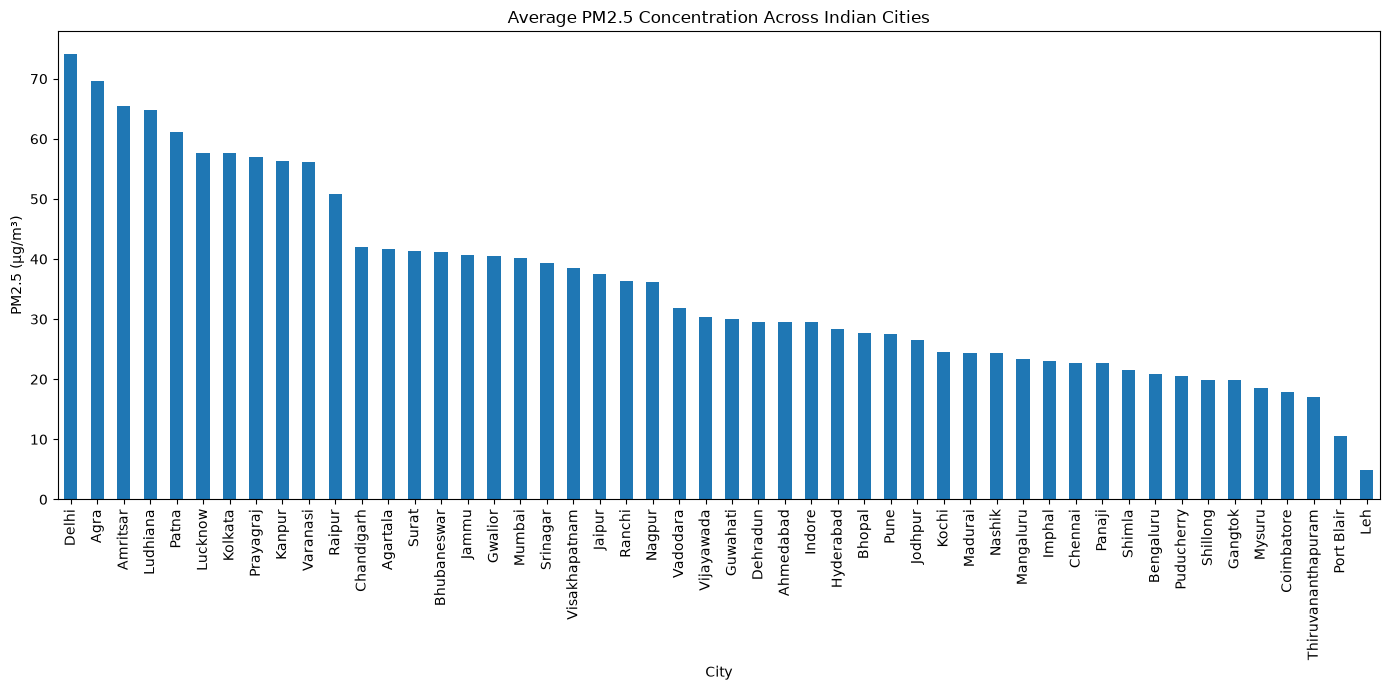

In [7]:
#Avg PM2.5 by city
city_pollution = (
    merged.groupby("city")["pm2_5_mean"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize = (14, 7))

city_pollution.plot(kind = "bar")

plt.title("Average PM2.5 Concentration Across Indian Cities")
plt.xlabel("City")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation = 90)
plt.tight_layout()
plt.show()

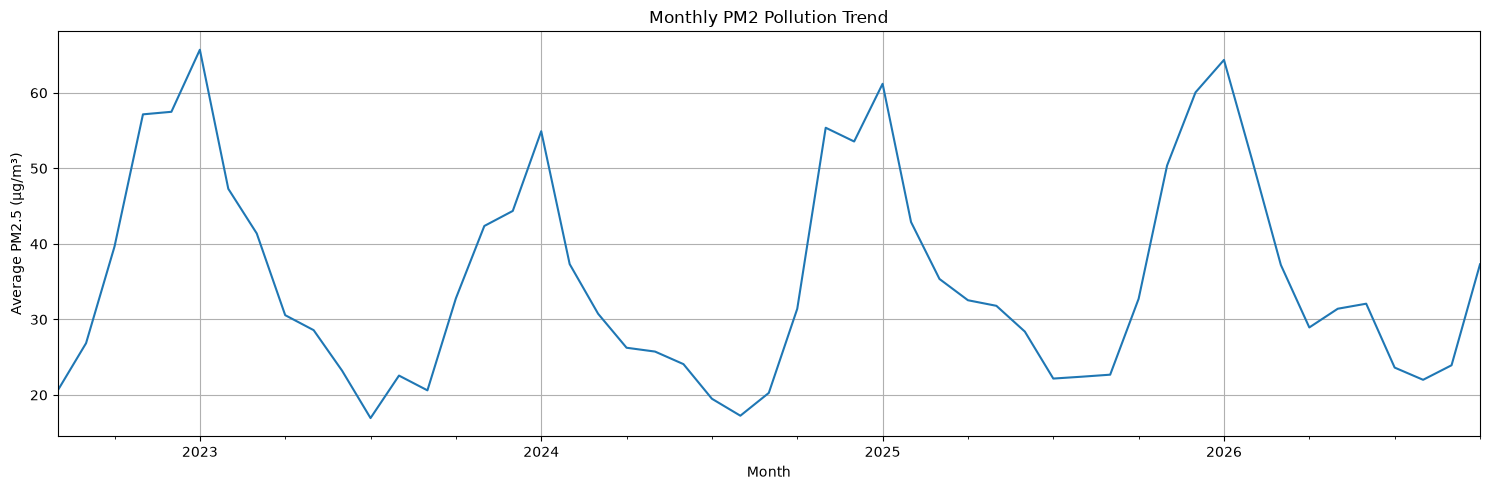

In [8]:
#Monthly population trend
monthly = merged.copy()

monthly["month_year"] = (
    monthly["date"].dt.to_period("M")
)

trend = monthly.groupby(
    "month_year"
)["pm2_5_mean"].mean()

plt.figure(figsize=(15, 5))

trend.plot()

plt.title("Monthly PM2 Pollution Trend")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.grid(True)
plt.tight_layout()
plt.show()

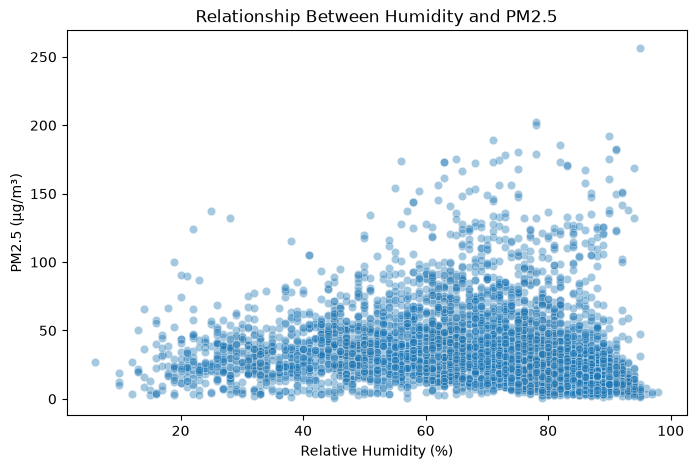

In [9]:
#Weather versus PM2.5
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=merged.sample(5000, random_state=42),
    x="relative_humidity_2m_mean",
    y="pm2_5_mean",
    alpha=0.4
)

plt.title("Relationship Between Humidity and PM2.5")
plt.xlabel("Relative Humidity (%)")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

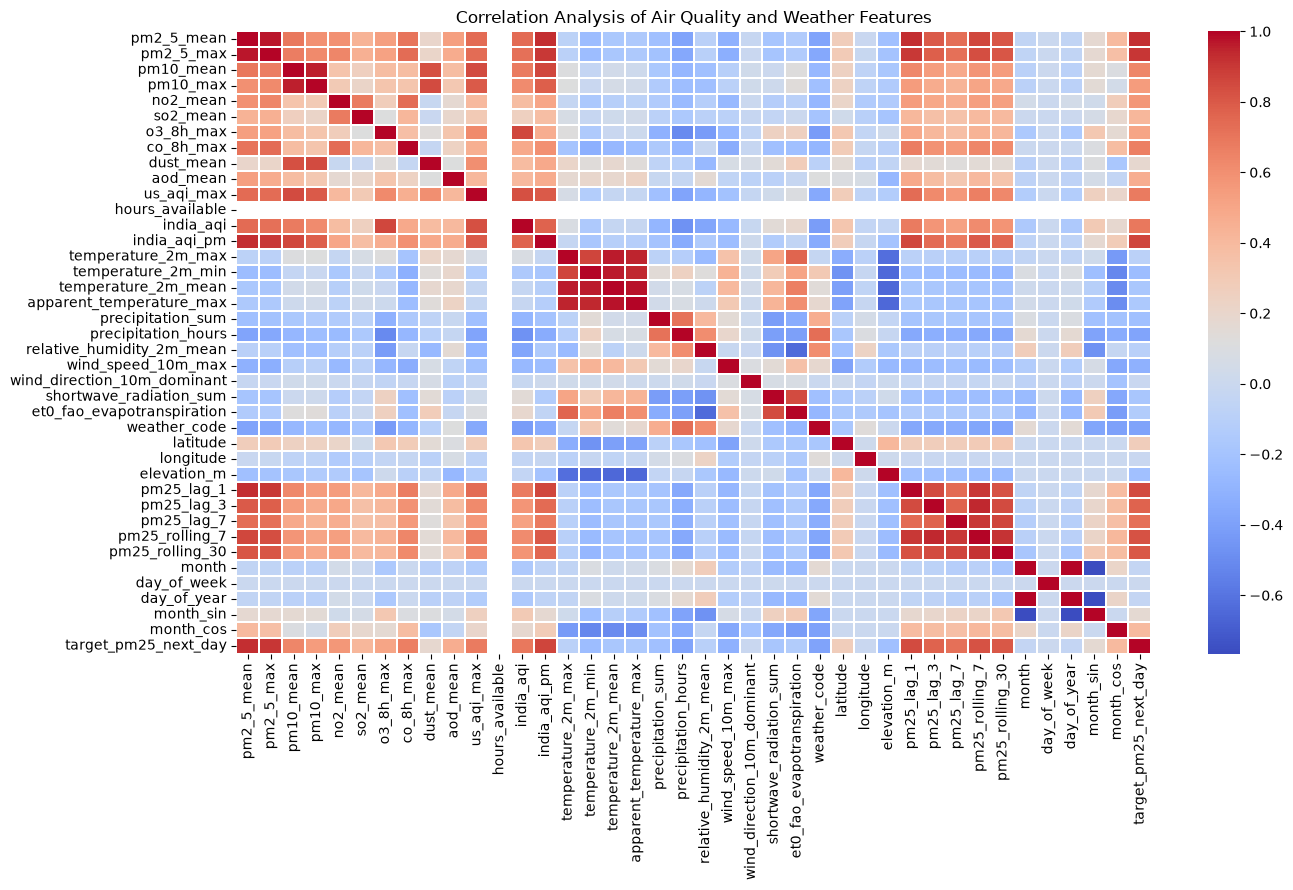

In [10]:
#Correlation heatmap
plt.figure(figsize=(14, 9))

numeric_data = merged.select_dtypes(include=np.number)

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Analysis of Air Quality and Weather Features")
plt.tight_layout()
plt.show()

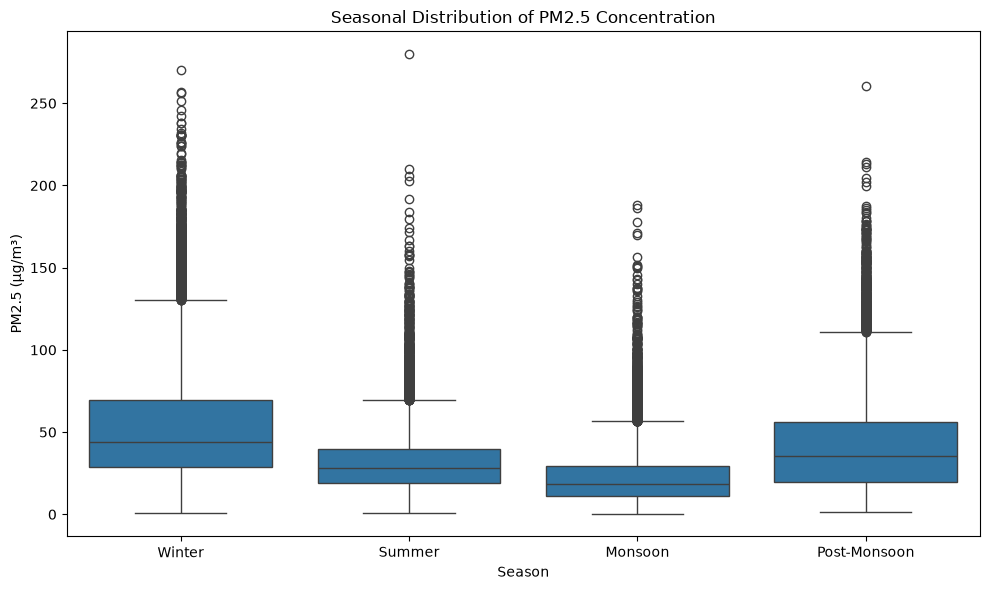

In [11]:
#Seasonal pollution distribution
merged["season"] = merged["date"].dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Summer", 4: "Summer", 5: "Summer",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon",
    9: "Monsoon", 10: "Post-Monsoon", 11: "Post-Monsoon"
})

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=merged,
    x="season",
    y="pm2_5_mean",
    order=["Winter", "Summer", "Monsoon", "Post-Monsoon"]
)

plt.title("Seasonal Distribution of PM2.5 Concentration")
plt.xlabel("Season")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

In [12]:
# Target variable
target = "target_pm25_next_day"

# Select available numerical features
numeric_features = [
    "pm2_5_mean",
    "pm10_mean",
    "no2_mean",
    "so2_mean",
    "pm25_lag_1",
    "pm25_lag_3",
    "pm25_lag_7",
    "pm25_rolling_7",
    "pm25_rolling_30",
    "temperature_2m_mean",
    "precipitation_sum",
    "relative_humidity_2m_mean",
    "wind_speed_10m_max",
    "elevation_m",
    "month",
    "day_of_week",
    "day_of_year",
    "month_sin",
    "month_cos"
]

numeric_features = [
    col for col in numeric_features
    if col in model_data.columns
]

# Categorical features
categorical_features = [
    col for col in ["city", "state", "region"]
    if col in model_data.columns
]

features = numeric_features + categorical_features

# Remove missing and infinite values in selected fields
model_data = model_data.replace(
    [np.inf, -np.inf], np.nan
)

model_data = model_data.dropna(
    subset=features + [target]
).copy()

print("Number of features:", len(features))
print("Final dataset shape:", model_data.shape)
print("Target:", target)

display(model_data[features + [target]].head())

Number of features: 22
Final dataset shape: (75850, 47)
Target: target_pm25_next_day


,pm2_5_mean,pm10_mean,no2_mean,so2_mean,pm25_lag_1,pm25_lag_3,pm25_lag_7,pm25_rolling_7,pm25_rolling_30,temperature_2m_mean,...,elevation_m,month,day_of_week,day_of_year,month_sin,month_cos,city,state,region,target_pm25_next_day
30,15.15,22.14,26.82,2.15,18.52,17.55,18.45,20.808571,16.651667,27.4,...,12.0,9,6,247,-1.0,-1.836970e-16,Agartala,Tripura,Northeast,12.49
31,12.49,18.03,27.93,2.00,15.15,20.75,24.18,20.337143,16.687000,27.1,...,12.0,9,0,248,-1.0,-1.836970e-16,Agartala,Tripura,Northeast,18.20
32,18.20,26.65,26.20,1.74,12.49,18.52,26.51,18.667143,16.699333,27.5,...,12.0,9,1,249,-1.0,-1.836970e-16,Agartala,Tripura,Northeast,24.50
33,24.50,35.29,38.95,1.36,18.20,15.15,19.70,17.480000,16.911000,29.0,...,12.0,9,2,250,-1.0,-1.836970e-16,Agartala,Tripura,Northeast,24.84
34,24.84,35.57,42.90,2.38,24.50,12.49,17.55,18.165714,17.418333,29.6,...,12.0,9,3,251,-1.0,-1.836970e-16,Agartala,Tripura,Northeast,32.13


In [13]:
#train-test split
unique_dates = np.sort(
    model_data["date"].unique()
)

split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

train_data = model_data[
    model_data["date"] < split_date
].copy()

test_data = model_data[
    model_data["date"] >= split_date
].copy()

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training ends:", train_data["date"].max())
print("Testing starts:", test_data["date"].min())

Training records: 60650
Testing records: 15200
Training ends: 2025-12-29 00:00:00
Testing starts: 2025-12-30 00:00:00


Model training and validation

In [14]:
#Prepare preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_features = [
    col for col in features
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(features))

Numerical features: 19
Categorical features: 3
Total features: 22


In [15]:
#Create chronological validation data
train_dates = np.sort(train_data["date"].unique())

val_index = int(len(train_dates) * 0.80)
val_start = train_dates[val_index]

sub_train = train_data[
    train_data["date"] < val_start
].copy()

validation = train_data[
    train_data["date"] >= val_start
].copy()

X_sub_train = sub_train[features]
y_sub_train = sub_train[target]

X_val = validation[features]
y_val = validation[target]

print("Training:", X_sub_train.shape)
print("Validation:", X_val.shape)
print("Validation starts:", validation["date"].min())

Training: (48500, 22)
Validation: (12150, 22)
Validation starts: 2025-05-01 00:00:00


In [16]:
#Train all three models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=4
    )
}

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

validation_results = []
trained_pipelines = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    print(f"\nTraining {name}...")

    pipeline.fit(X_sub_train, y_sub_train)

    predictions = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    validation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_pipelines[name] = pipeline

    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2:", round(r2, 4))

validation_df = pd.DataFrame(validation_results)

display(
    validation_df.sort_values("RMSE")
)


Training Linear Regression...
MAE: 6.2503
RMSE: 9.4805
R2: 0.8886

Training Decision Tree...
MAE: 7.624
RMSE: 11.9797
R2: 0.8221

Training Random Forest...
MAE: 6.7096
RMSE: 10.4258
R2: 0.8652


,Model,MAE,RMSE,R2
0,Linear Regression,6.250334,9.480525,0.888567
2,Random Forest,6.709594,10.425801,0.865238
1,Decision Tree,7.623980,11.979711,0.822074


Hyperparameter tuning

In [17]:

from sklearn.model_selection import ParameterGrid

parameter_grids = {
    "Decision Tree": {
        "model__max_depth": [10, 15, 20],
        "model__min_samples_leaf": [2, 5]
    },

    "Random Forest": {
         "model__n_estimators": [30, 50],
        "model__max_depth": [10, 12],
        "model__min_samples_leaf": [5]
    }
}

tuned_models = {}

for name, grid in parameter_grids.items():

    print("\nTuning:", name)

    best_rmse = float("inf")
    best_pipeline = None
    best_params = None

    for params in ParameterGrid(grid):

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", models[name].__class__(
                random_state=42,
                **{
                    k.replace("model__", ""): v
                    for k, v in params.items()
                },
                **({"n_jobs": 4} if name == "Random Forest" else {})
            ))
        ])

        pipeline.fit(X_sub_train, y_sub_train)

        predictions = pipeline.predict(X_val)

        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )

        if rmse < best_rmse:
            best_rmse = rmse
            best_pipeline = pipeline
            best_params = params

    tuned_models[name] = best_params

    print("Best parameters:", best_params)
    print("Best validation RMSE:", round(best_rmse, 4))


Tuning: Decision Tree
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5}
Best validation RMSE: 10.668

Tuning: Random Forest
Best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 5, 'model__n_estimators': 50}
Best validation RMSE: 9.5538


Final evaluation on the test dataset

In [18]:
final_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        **{
            k.replace("model__", ""): v
            for k, v in tuned_models["Decision Tree"].items()
        },
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        **{
            k.replace("model__", ""): v
            for k, v in tuned_models["Random Forest"].items()
        },
        random_state=42,
        n_jobs=4
    )
}

final_results = []
final_pipelines = {}
test_predictions = {}

for name, model in final_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    final_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    final_pipelines[name] = pipeline
    test_predictions[name] = predictions

    print(f"\n{name}")
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2:", round(r2, 4))

results_df = pd.DataFrame(final_results).sort_values("RMSE")

display(results_df)


Linear Regression
MAE: 6.6813
RMSE: 10.0826
R2: 0.8649

Decision Tree
MAE: 7.0392
RMSE: 10.9133
R2: 0.8418

Random Forest
MAE: 6.5988
RMSE: 10.0266
R2: 0.8664


,Model,MAE,RMSE,R2
2,Random Forest,6.598846,10.026574,0.866446
0,Linear Regression,6.681342,10.082632,0.864948
1,Decision Tree,7.039235,10.913313,0.841778


Model comparison graph

,Model,MAE,RMSE,R2 Score
0,Linear Regression,6.6813,10.0826,0.8649
1,Decision Tree,7.0392,10.9133,0.8418
2,Random Forest,6.5988,10.0266,0.8664


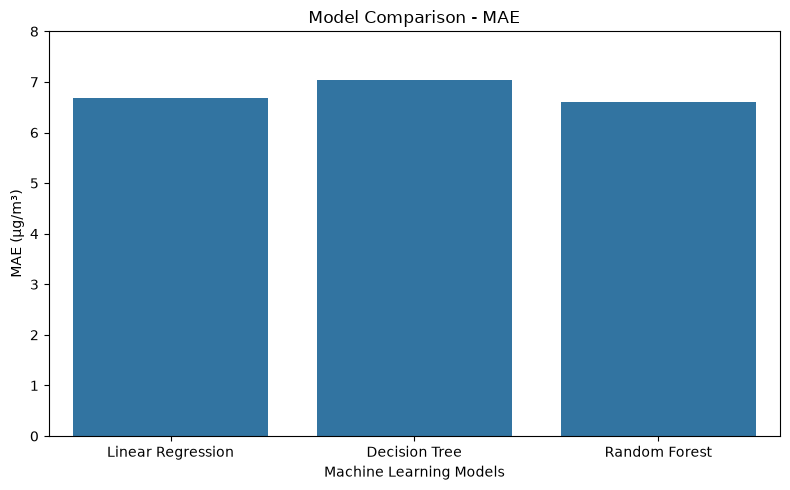

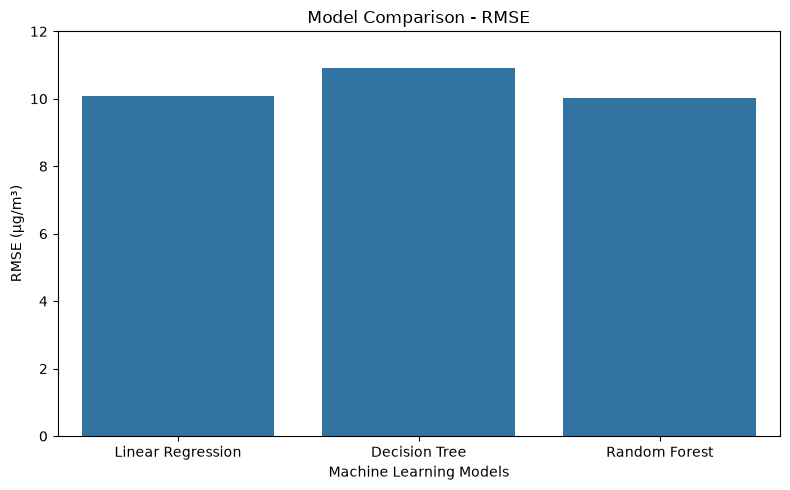

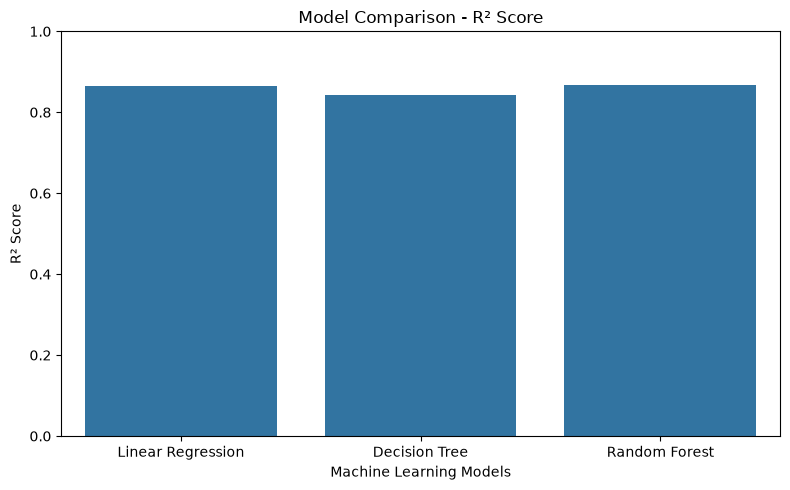

In [19]:

# Model Comparison Using Final Test Results

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Store final test results
comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [6.681342, 7.039235, 6.598846],
    "RMSE": [10.082632, 10.913313, 10.026574],
    "R2 Score": [0.864948, 0.841778, 0.866446]
})

# Display comparison table
display(comparison_df.round(4))

# 1. MAE Comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x="Model", y="MAE")
plt.title("Model Comparison - MAE")
plt.xlabel("Machine Learning Models")
plt.ylabel("MAE (µg/m³)")
plt.ylim(0, 8)
plt.tight_layout()
plt.show()

# 2. RMSE Comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x="Model", y="RMSE")
plt.title("Model Comparison - RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE (µg/m³)")
plt.ylim(0, 12)
plt.tight_layout()
plt.show()

# 3. R2 Score Comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x="Model", y="R2 Score")
plt.title("Model Comparison - R² Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


,Feature,Importance
0,num__pm2_5_mean,0.934820
4,num__pm25_lag_1,0.010919
8,num__pm25_rolling_30,0.009343
12,num__wind_speed_10m_max,0.004843
6,num__pm25_lag_7,0.004053
5,num__pm25_lag_3,0.004023
16,num__day_of_year,0.003651
10,num__precipitation_sum,0.003606
9,num__temperature_2m_mean,0.003478
7,num__pm25_rolling_7,0.003374


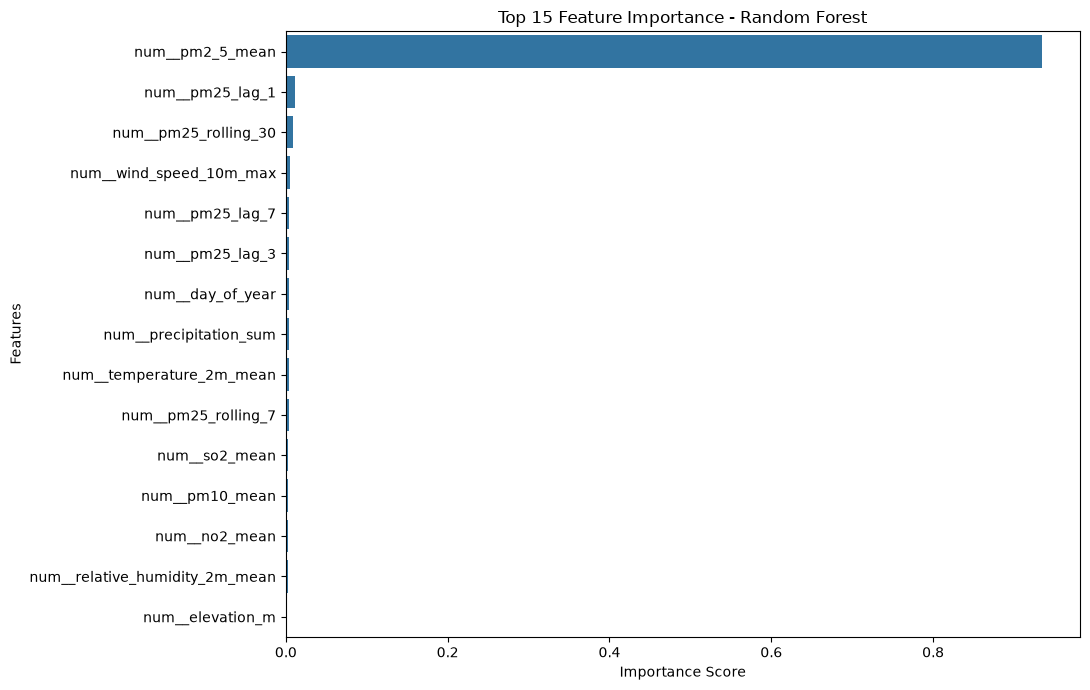

In [20]:
# Random Forest Feature Importance Analysis

# Get the final trained Random Forest pipeline
rf_pipeline = final_pipelines["Random Forest"]

# Extract the trained Random Forest model
rf_model = rf_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    rf_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract feature importance scores
importance_values = rf_model.feature_importances_

# Create feature importance dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 important features
display(importance_df.head(15))

# Plot top 15 features
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

Actual vs Predicted graph

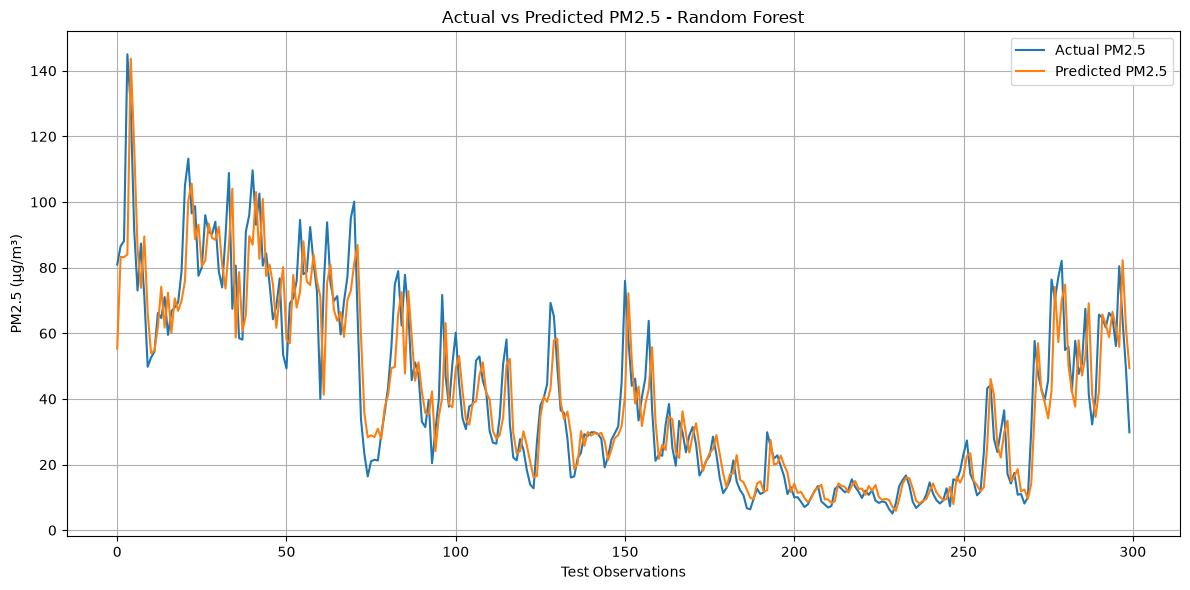

In [21]:
best_model_name = results_df.iloc[0]["Model"]

best_predictions = test_predictions[best_model_name]

plt.figure(figsize=(12, 6))

plt.plot(
    np.array(y_test)[:300],
    label="Actual PM2.5"
)

plt.plot(
    best_predictions[:300],
    label="Predicted PM2.5"
)

plt.title(f"Actual vs Predicted PM2.5 - {best_model_name}")
plt.xlabel("Test Observations")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Best Model: Random Forest
Mean Residual: 0.0569
Residual Standard Deviation: 10.0264


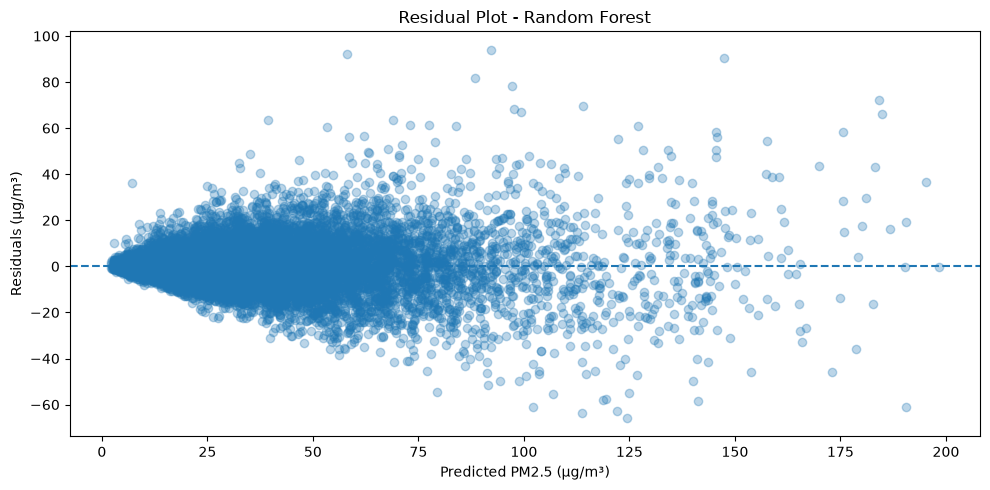

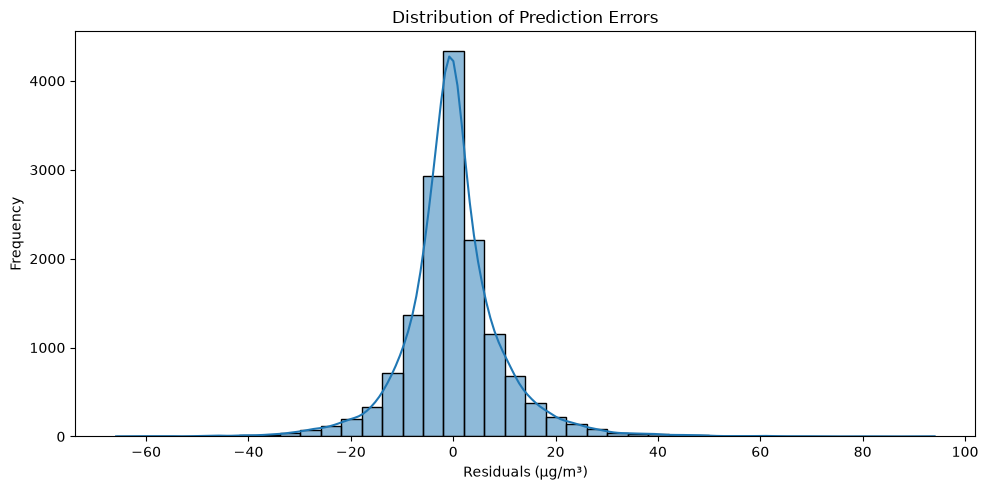

In [22]:

# Residual Error Analysis

# Select the best model
best_model_name = results_df.iloc[0]["Model"]

# Get actual and predicted values
actual_values = np.array(y_test)
predicted_values = test_predictions[best_model_name]

# Calculate residuals
residuals = actual_values - predicted_values

print("Best Model:", best_model_name)
print("Mean Residual:", round(np.mean(residuals), 4))
print("Residual Standard Deviation:", round(np.std(residuals), 4))

# Graph 1: Actual vs Residuals
plt.figure(figsize=(10, 5))

plt.scatter(
    predicted_values,
    residuals,
    alpha=0.3
)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot - " + best_model_name)
plt.xlabel("Predicted PM2.5 (µg/m³)")
plt.ylabel("Residuals (µg/m³)")
plt.tight_layout()
plt.show()

# Graph 2: Distribution of Residuals
plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residuals (µg/m³)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [23]:

# Baseline Model: Tomorrow's PM2.5 = Today's PM2.5

baseline_predictions = X_test["pm2_5_mean"].values

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

print("Baseline Model Results")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2 Score:", round(baseline_r2, 4))


Baseline Model Results
MAE: 6.9836
RMSE: 10.7533
R2 Score: 0.8464


,Feature,Importance,Std
0,pm2_5_mean,18.03459,0.11758
4,pm25_lag_1,0.66850,0.01075
8,pm25_rolling_30,0.62284,0.01683
10,precipitation_sum,0.11153,0.01109
12,wind_speed_10m_max,0.05214,0.00523
5,pm25_lag_3,0.02842,0.00220
6,pm25_lag_7,0.02610,0.00188
3,so2_mean,0.02232,0.00240
1,pm10_mean,0.02186,0.00332
7,pm25_rolling_7,0.02054,0.00259


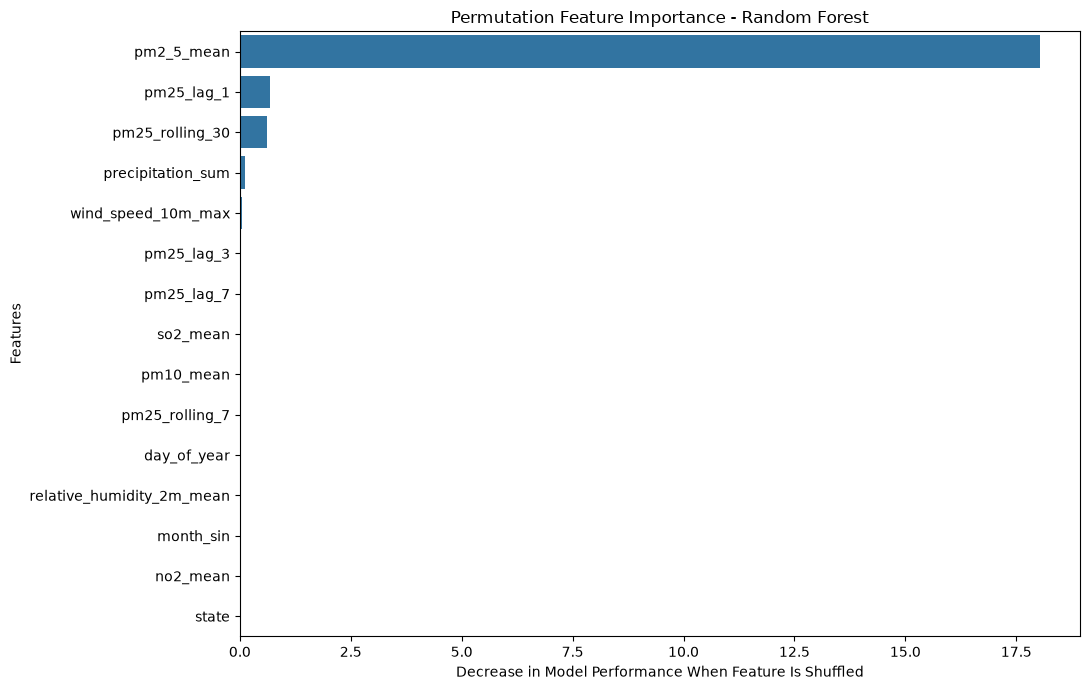

In [24]:
# Permutation Feature Importance on Test Data

from sklearn.inspection import permutation_importance

# Use the final trained Random Forest pipeline
rf_pipeline = final_pipelines["Random Forest"]

# Calculate permutation importance
perm_result = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

# Create importance dataframe
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(permutation_df.head(15).round(5))

# Plot top 15 features
plt.figure(figsize=(11, 7))

sns.barplot(
    data=permutation_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance - Random Forest")
plt.xlabel("Decrease in Model Performance When Feature Is Shuffled")
plt.ylabel("Features")
plt.tight_layout()
plt.show()
